# Taller integrador - Gestión de requisitos de software

**Proyecto:** Programa de respuesta automática de correos electrónicos.

Este notebook construye la matriz de trazabilidad y el resumen de solicitudes de cambio. Los nombres de archivos de código son módulos propuestos para relacionar los requisitos con una futura implementación; no significan que el sistema de correo ya esté programado.

## Parte 6. Matriz de trazabilidad en Python / Colab
Primero se importan las librerías y se registra la misma matriz presentada en el documento.

In [1]:
import pandas as pd

datos = [
    {
        "Necesidad": "N-01: conectar una cuenta", "Requisito": "RF-01",
        "Historia": "US-01", "Caso_Uso": "CU-01", "Diseño": "DS-01",
        "Codigo": "src/auth_mail.py", "Prueba": "TC-01"
    },
    {
        "Necesidad": "N-02: identificar mensajes nuevos", "Requisito": "RF-02",
        "Historia": "US-02", "Caso_Uso": "CU-02", "Diseño": "DS-02",
        "Codigo": "src/mail_reader.py", "Prueba": "TC-02"
    },
    {
        "Necesidad": "N-03: organizar correos", "Requisito": "RF-03",
        "Historia": "US-03", "Caso_Uso": "CU-03", "Diseño": "DS-03",
        "Codigo": "src/classifier.py", "Prueba": "TC-03"
    },
    {
        "Necesidad": "N-04: reducir redacción manual", "Requisito": "RF-04",
        "Historia": "US-04", "Caso_Uso": "CU-04", "Diseño": "DS-04",
        "Codigo": "src/response_generator.py", "Prueba": "TC-04"
    },
    {
        "Necesidad": "N-05: revisar antes de enviar", "Requisito": "RF-05",
        "Historia": "US-05", "Caso_Uso": "CU-05", "Diseño": "DS-05",
        "Codigo": "src/approval_view.py", "Prueba": "TC-05"
    },
    {
        "Necesidad": "N-06: proteger la cuenta", "Requisito": "RNF-01",
        "Historia": "US-06", "Caso_Uso": "CU-01", "Diseño": "DS-01",
        "Codigo": "src/auth_mail.py", "Prueba": "TC-06"
    },
    {
        "Necesidad": "N-07: restringir el acceso al correo", "Requisito": "RNF-02",
        "Historia": "US-07", "Caso_Uso": "CU-06", "Diseño": "DS-06",
        "Codigo": "src/access_control.py", "Prueba": "TC-07"
    },
    {
        "Necesidad": "N-08: evitar respuestas duplicadas", "Requisito": "RNF-03",
        "Historia": "US-08", "Caso_Uso": "CU-07", "Diseño": "DS-07",
        "Codigo": "src/send_control.py", "Prueba": "TC-08"
    }
]

df = pd.DataFrame(datos)
display(df)

,Necesidad,Requisito,Historia,Caso_Uso,Diseño,Codigo,Prueba
0,N-01: conectar una cuenta,RF-01,US-01,CU-01,DS-01,src/auth_mail.py,TC-01
1,N-02: identificar mensajes nuevos,RF-02,US-02,CU-02,DS-02,src/mail_reader.py,TC-02
2,N-03: organizar correos,RF-03,US-03,CU-03,DS-03,src/classifier.py,TC-03
3,N-04: reducir redacción manual,RF-04,US-04,CU-04,DS-04,src/response_generator.py,TC-04
4,N-05: revisar antes de enviar,RF-05,US-05,CU-05,DS-05,src/approval_view.py,TC-05
5,N-06: proteger la cuenta,RNF-01,US-06,CU-01,DS-01,src/auth_mail.py,TC-06
6,N-07: restringir el acceso al correo,RNF-02,US-07,CU-06,DS-06,src/access_control.py,TC-07
7,N-08: evitar respuestas duplicadas,RNF-03,US-08,CU-07,DS-07,src/send_control.py,TC-08


### Función para encontrar trazabilidad incompleta
La función revisa si faltan historia de usuario, caso de uso, archivo de código o prueba. Si una celda está vacía, informa cuál es el requisito y qué dato falta.

In [2]:
def revisar_trazabilidad(matriz):
    columnas_obligatorias = ["Historia", "Caso_Uso", "Codigo", "Prueba"]
    faltantes = []

    for _, fila in matriz.iterrows():
        for columna in columnas_obligatorias:
            valor = fila[columna]
            if pd.isna(valor) or str(valor).strip() == "":
                faltantes.append({
                    "Requisito": fila["Requisito"],
                    "Elemento faltante": columna
                })

    resultado = pd.DataFrame(faltantes, columns=["Requisito", "Elemento faltante"])
    if resultado.empty:
        print("No se encontraron requerimientos con trazabilidad incompleta.")
    else:
        print("Se encontraron los siguientes elementos sin relacionar:")
        display(resultado)
    return resultado

# Revisión de la matriz completa
incompletos = revisar_trazabilidad(df)

No se encontraron requerimientos con trazabilidad incompleta.


### Comprobación de la función
Para comprobar que la función detecta un dato faltante, se crea una copia temporal de la matriz y se borra solamente la prueba de RNF-03. La matriz original `df` no cambia.

In [3]:
matriz_prueba = df.copy()
matriz_prueba.loc[matriz_prueba["Requisito"] == "RNF-03", "Prueba"] = ""
revisar_trazabilidad(matriz_prueba)

Se encontraron los siguientes elementos sin relacionar:


,Requisito,Elemento faltante
0,RNF-03,Prueba


,Requisito,Elemento faltante
0,RNF-03,Prueba


**Pregunta:** ¿Qué riesgo existe si un requerimiento está implementado pero no tiene prueba asociada?

**Respuesta:** No se puede comprobar objetivamente que la función cumple lo solicitado. El sistema podría tener errores que pasen inadvertidos, afectar al usuario y generar retrabajo. Además, no queda evidencia de que el requerimiento fue validado.

## Parte 15. Control de cambios en Python
Se registran cuatro movimientos para mostrar los tres estados que pide la guía. CR-01 es la solicitud propuesta para el requerimiento de aprobación manual; CR-02 y CR-03 son ejemplos académicos para probar el reporte; CR-SEG-01 corresponde al escenario hipotético de seguridad de la parte 16.

In [4]:
cambios = [
    {"id": "CR-01", "requisito": "RF-05", "version_anterior": "1.1",
     "version_nueva": "1.2", "prioridad": "Alta", "impacto": "Medio", "estado": "Aprobado"},
    {"id": "CR-02", "requisito": "RF-02", "version_anterior": "1.0",
     "version_nueva": "1.1", "prioridad": "Media", "impacto": "Medio", "estado": "Pendiente"},
    {"id": "CR-03", "requisito": "RF-05", "version_anterior": "1.2",
     "version_nueva": "1.3", "prioridad": "Baja", "impacto": "Alto", "estado": "Rechazado"},
    {"id": "CR-SEG-01", "requisito": "RNF-01", "version_anterior": "1.0",
     "version_nueva": "1.1", "prioridad": "Alta", "impacto": "Alto", "estado": "Pendiente"}
]

cambios_df = pd.DataFrame(cambios)
display(cambios_df)

,id,requisito,version_anterior,version_nueva,prioridad,impacto,estado
0,CR-01,RF-05,1.1,1.2,Alta,Medio,Aprobado
1,CR-02,RF-02,1.0,1.1,Media,Medio,Pendiente
2,CR-03,RF-05,1.2,1.3,Baja,Alto,Rechazado
3,CR-SEG-01,RNF-01,1.0,1.1,Alta,Alto,Pendiente


### Resumen automático de cambios

In [5]:
print("Cantidad total de cambios:", len(cambios_df))
print("Cambios aprobados:", (cambios_df["estado"] == "Aprobado").sum())
print("Cambios rechazados:", (cambios_df["estado"] == "Rechazado").sum())
print("Cambios pendientes:", (cambios_df["estado"] == "Pendiente").sum())

print("\nCambios por prioridad:")
display(cambios_df["prioridad"].value_counts().rename_axis("Prioridad").reset_index(name="Cantidad"))

print("Requerimientos más modificados:")
display(cambios_df["requisito"].value_counts().rename_axis("Requisito").reset_index(name="Cantidad de cambios"))

Cantidad total de cambios: 4
Cambios aprobados: 1
Cambios rechazados: 1
Cambios pendientes: 2

Cambios por prioridad:


,Prioridad,Cantidad
0,Alta,2
1,Media,1
2,Baja,1


Requerimientos más modificados:


,Requisito,Cantidad de cambios
0,RF-05,2
1,RF-02,1
2,RNF-01,1


### Gráfico 1. Cantidad de cambios por estado

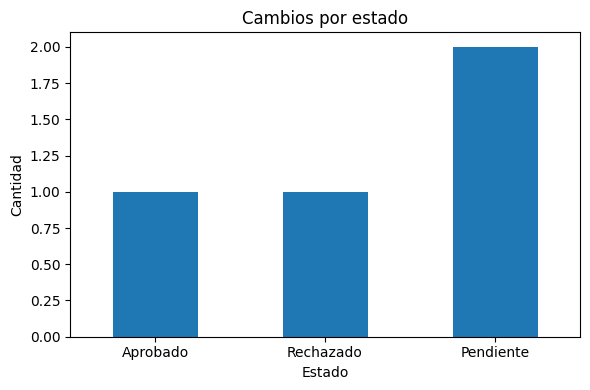

In [6]:
import matplotlib.pyplot as plt

orden_estados = ["Aprobado", "Rechazado", "Pendiente"]
conteo_estados = cambios_df["estado"].value_counts().reindex(orden_estados, fill_value=0)

plt.figure(figsize=(6, 4))
conteo_estados.plot(kind="bar")
plt.title("Cambios por estado")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Gráfico 2. Cantidad de cambios por prioridad

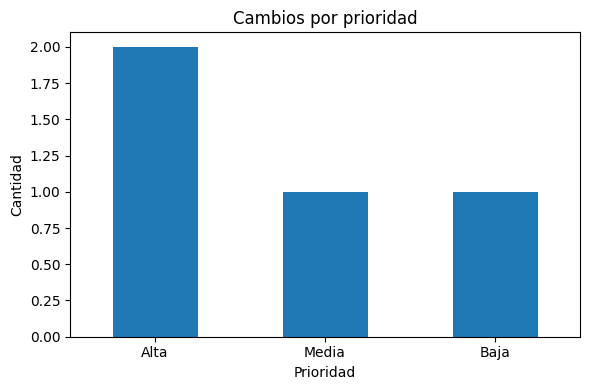

In [7]:
orden_prioridad = ["Alta", "Media", "Baja"]
conteo_prioridad = cambios_df["prioridad"].value_counts().reindex(orden_prioridad, fill_value=0)

plt.figure(figsize=(6, 4))
conteo_prioridad.plot(kind="bar")
plt.title("Cambios por prioridad")
plt.xlabel("Prioridad")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretación
En los datos de ejemplo hay cuatro solicitudes: una aprobada, una rechazada y dos pendientes. La prioridad alta aparece en dos solicitudes. RF-05 es el requisito con más cambios registrados, porque aparece en CR-01 y CR-03. Los conteos cambian automáticamente si se agregan, eliminan o actualizan registros en la lista `cambios`.